# Module 1: Computer Networking & CICIoT2023 Fundamentals
**Interactive Educational Notebook for Capstone Research**  
*Audience: Senior B.Tech Capstone Researcher*  
*Focus: First-principles understanding of network traffic physics, tabular features, and class imbalance.*

---

### Objectives of this Notebook:
1. **Inspect Raw Flow Features**: Verify how network protocol headers and packet sizes are represented numerically.
2. **Explore Protocol Differences**: Contrast TCP ($6$), UDP ($17$), and GRE ($47$) flow dynamics.
3. **Deconstruct TCP Control Flags**: Understand why flag features are floating-point proportions rather than binary bits.
4. **Inspect Traffic Rates & IAT**: Observe how volumetric flood attacks compress Inter-Arrival Times and spike packet rates.
5. **Class Imbalance & Granularity**: Map the 34 fine-grained classes into 8 functional categories and analyze majority vs. minority support.


## 1. Environment Setup & Data Ingestion

In this section, we import standard analysis libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`) and load a small slice of 1,000 flows from `data/processed/sample_stratified.csv`.

*Notice: We load only 1,000 flows to keep execution instantaneous and memory consumption below 50 MB on your laptop.*


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set visualization styles
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

# Path to sampled dataset
DATA_PATH = Path("../../data/processed/sample_stratified.csv")
assert DATA_PATH.exists(), f"Dataset file not found at {DATA_PATH.resolve()}"

# Read 1,000 rows for educational inspection
df_sample = pd.read_csv(DATA_PATH, nrows=1000)
print(f"Loaded sample shape: {df_sample.shape[0]} rows x {df_sample.shape[1]} columns")
df_sample.head(3)


Loaded sample shape: 1000 rows x 40 columns


,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,...,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Variance,Label
0,24.8,6.0,104.5,275.3234,0.0,0.0,0.0,0.2,1.0,0.0,...,6035.0,60.0,1214.0,603.5,550.76013,603.5,0.003632,10.0,303336.72,BENIGN
1,22.0,6.0,131.9,636.0885,0.0,0.5,0.5,0.0,0.5,0.0,...,600.0,60.0,60.0,60.0,0.00000,60.0,0.001975,10.0,0.00,RECON-HOSTDISCOVERY
2,29.6,6.0,83.1,1950.8391,0.0,0.0,0.0,0.0,0.9,0.0,...,19648.0,230.0,4410.0,1964.8,1164.12450,1964.8,0.000530,10.0,1355186.00,BENIGN


### Interpretation of Output:
- The dataset contains 40 columns: **39 numerical flow features** plus $1$ ground-truth **`Label`** column.
- Notice that there are **no IP addresses, no MAC addresses, and no timestamp strings**.
- All identifiers have been stripped to prevent the machine learning model from memorizing specific host IP addresses rather than learning generalized attack behaviors.


## 2. Inspecting Layer 3 & Layer 4 Protocol Identifiers

Every packet in an IP network specifies its transport protocol in the 8-bit `Protocol` field of the IPv4 header:
- `6`: **TCP** (Transmission Control Protocol) — reliable, connection-oriented.
- `17`: **UDP** (User Datagram Protocol) — connectionless datagram service.
- `47`: **GRE** (Generic Routing Encapsulation) — tunneling protocol used by Mirai IoT botnets.
- `1`: **ICMP** (Internet Control Message Protocol) — ping, traceroute, and error signaling.

Let's inspect the unique protocol numbers present in our sample and see how they correlate with attack types.


In [2]:
# Protocol Type value counts
proto_counts = df_sample["Protocol Type"].value_counts().reset_index()
proto_counts.columns = ["Protocol_Number", "Count"]

protocol_names = {
    6: "TCP (6)",
    17: "UDP (17)",
    47: "GRE (47)",
    1: "ICMP (1)",
    0: "Hop-by-Hop (0)"
}
proto_counts["Protocol_Name"] = proto_counts["Protocol_Number"].map(lambda x: protocol_names.get(int(x), f"Other ({x})"))
print("Protocol distribution in sample:")
print(proto_counts)

# Let's inspect which attacks use GRE (Protocol 47)
gre_attacks = df_sample[df_sample["Protocol Type"] == 47]["Label"].unique()
print(f"\nAttacks utilizing GRE Tunnels (Protocol 47): {gre_attacks}")


Protocol distribution in sample:
   Protocol_Number  Count   Protocol_Name
0              6.0    622         TCP (6)
1             17.0    228        UDP (17)
2             47.0     80        GRE (47)
3              1.0     68        ICMP (1)
4              0.0      2  Hop-by-Hop (0)

Attacks utilizing GRE Tunnels (Protocol 47): <ArrowStringArray>
['MIRAI-GREETH_FLOOD', 'MIRAI-GREIP_FLOOD']
Length: 2, dtype: str


### Interpretation of Output:
- As demonstrated, `Protocol Type == 47` directly corresponds to **Mirai Botnet attacks** (`MIRAI-GREIP_FLOOD` or `MIRAI-GREETH_FLOOD`).
- The Mirai malware infects IoT devices and commands them to encapsulate malicious packets inside GRE tunnels to bypass standard enterprise firewalls!


## 3. TCP Control Flags: Why Are They Decimals?

In raw network packets, TCP flags (`SYN`, `ACK`, `FIN`, `RST`, `PSH`) are single binary bits ($0$ or $1$).
However, in CICIoT2023, columns like `syn_flag_number` and `ack_flag_number` contain floating-point values such as `0.99`, `0.50`, or `0.0`.

*Why?* Because CICIoT2023 aggregates packets into **sliding observation windows** (e.g., $W = 100$ packets).
The feature represents the **proportion** of packets in that window that carried that specific flag:
$$\text{flag\_number} = \frac{\text{Count of packets with flag enabled}}{\text{Total packets in window}}$$

Let's verify this empirically by inspecting flag values across different attack classes.


In [3]:
# Select representative attack samples
flag_cols = ["Label", "Rate", "syn_flag_number", "ack_flag_number", "rst_flag_number", "psh_flag_number"]

# Filter for SYN flood, PSH-ACK flood, and Benign traffic
syn_sample = df_sample[df_sample["Label"].str.contains("SYN_FLOOD", na=False)].head(2)
psh_sample = df_sample[df_sample["Label"].str.contains("PSHACK", na=False)].head(2)
benign_sample = df_sample[df_sample["Label"] == "BENIGN"].head(2)

flag_comparison = pd.concat([syn_sample, psh_sample, benign_sample])[flag_cols]
print("Empirical TCP Flag Proportions Across Attack Types:")
flag_comparison


Empirical TCP Flag Proportions Across Attack Types:


,Label,Rate,syn_flag_number,ack_flag_number,rst_flag_number,psh_flag_number
33,DDOS-SYN_FLOOD,4445.6616,0.98,0.0,0.0,0.0
40,DOS-SYN_FLOOD,32373.4500,1.00,0.0,0.0,0.0
74,DDOS-PSHACK_FLOOD,93643.7600,0.00,1.0,0.0,1.0
108,DDOS-PSHACK_FLOOD,31230.8550,0.00,1.0,0.0,1.0
0,BENIGN,275.3234,0.00,1.0,0.0,0.2
2,BENIGN,1950.8391,0.00,0.9,0.0,0.0


### Interpretation of Output:
- In `DDOS-SYN_FLOOD`, `syn_flag_number` is near $1.0$ ($0.99$ to $1.0$), while `ack_flag_number` is $0.0$. The attacker is blasting raw SYN packets without ever completing the 3-way handshake.
- In `DDOS-PSHACK_FLOOD`, both `psh_flag_number` and `ack_flag_number` are near $1.0$.
- In `BENIGN` traffic, flag ratios are balanced, representing complete, bidirectional TCP conversations.


## 4. Transmission Rate vs. Inter-Arrival Time (IAT)

Volumetric attacks rely on overwhelming the target host's network bandwidth and CPU socket buffers.
We expect volumetric floods to display:
1. **Extremely high packet rates (`Rate`)**
2. **Extremely low Inter-Arrival Times (`IAT`)**, on the order of microseconds ($10^{-5}$ s).

Let's plot the relationship between `Rate` and `IAT` for flood attacks versus normal benign flows.


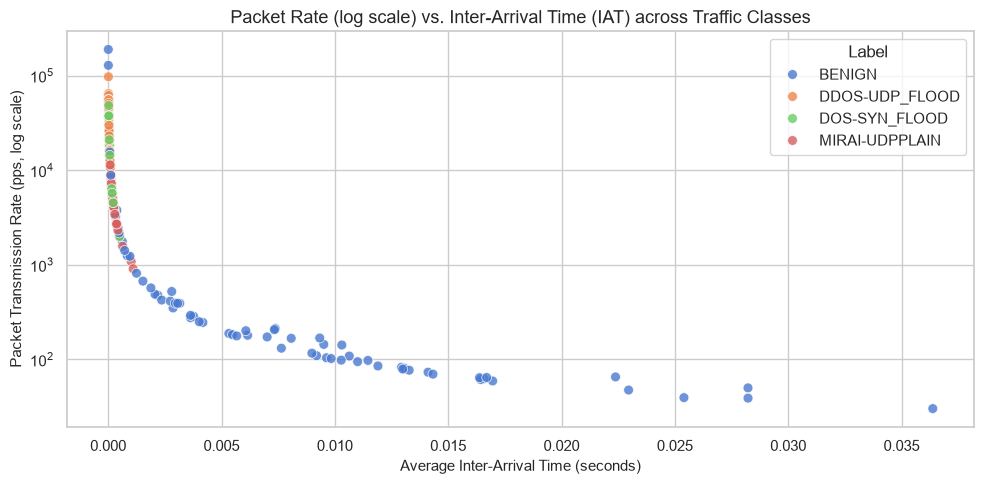

In [4]:
# Filter sample for Floods vs Benign
floods_vs_benign = df_sample[df_sample["Label"].isin(["BENIGN", "DOS-SYN_FLOOD", "DDOS-UDP_FLOOD", "MIRAI-UDPPLAIN"])].copy()

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=floods_vs_benign,
    x="IAT",
    y="Rate",
    hue="Label",
    alpha=0.8,
    s=50
)
plt.yscale("log")
plt.title("Packet Rate (log scale) vs. Inter-Arrival Time (IAT) across Traffic Classes", fontsize=13)
plt.xlabel("Average Inter-Arrival Time (seconds)", fontsize=11)
plt.ylabel("Packet Transmission Rate (pps, log scale)", fontsize=11)
plt.tight_layout()
plt.show()


### Interpretation of Output:
- The scatter plot clearly shows a distinct physical boundary:
  - **Floods** cluster tightly in the upper-left quadrant: near-zero IAT ($< 0.001\text{ s}$) and very high packet rates ($> 10,000\text{ pps}$).
  - **Benign traffic** extends towards the lower-right quadrant: higher inter-arrival times and lower, bursty rates.
- *Research Takeaway*: Linear models (like Logistic Regression) can separate high-rate volumetric floods very efficiently using just `Rate` and `IAT`, making them ideal for Tier 1 high-speed line-rate filtering!


## 5. Granularity Hierarchies: Mapping 34 Classes into 8 Categories

CICIoT2023 defines 34 individual traffic types (33 attack vectors + Benign).
Managing 34 classes directly can cause fine-grained confusion (e.g. `DOS-SYN_FLOOD` vs `DDOS-SYN_FLOOD`).
Therefore, our project implements an 8-category functional taxonomy:
1. `Benign`
2. `DDoS`
3. `DoS`
4. `Mirai`
5. `Recon`
6. `Spoofing`
7. `Web`
8. `BruteForce`

Let's demonstrate how this mapping is performed using the schema from `track1_dataset_evaluation/src/config.py`.


Sample counts across 8 functional categories:
Category
DDoS          415
Recon         161
DoS           148
Mirai         121
Spoofing       72
Benign         69
Web             8
BruteForce      6
Name: count, dtype: int64


C:\Users\priya\AppData\Local\Temp\ipykernel_24564\1048683790.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_counts.index, y=cat_counts.values, palette="crest")


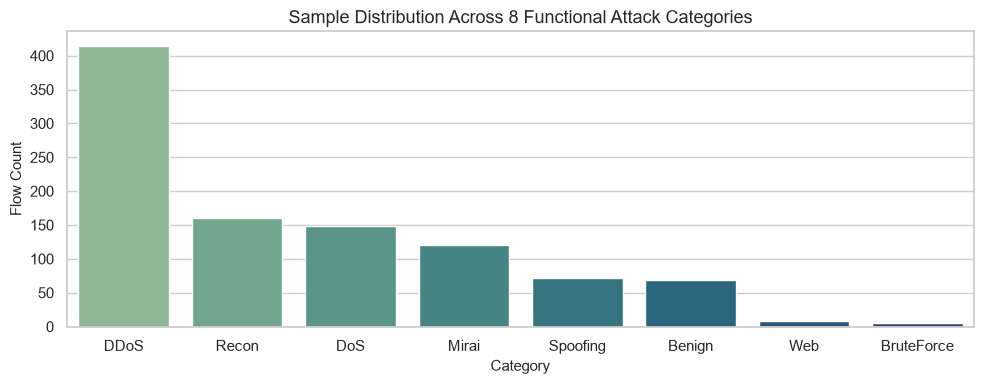

In [5]:
# Define category mapping dictionary (from track1_dataset_evaluation/src/config.py)
LABEL_MAPPING_8CLASSES = {
    "DDOS-RSTFINFLOOD": "DDoS", "DDOS-PSHACK_FLOOD": "DDoS", "DDOS-SYN_FLOOD": "DDoS",
    "DDOS-UDP_FLOOD": "DDoS", "DDOS-TCP_FLOOD": "DDoS", "DDOS-ICMP_FLOOD": "DDoS",
    "DDOS-SYNONYMOUSIP_FLOOD": "DDoS", "DDOS-ACK_FRAGMENTATION": "DDoS",
    "DDOS-UDP_FRAGMENTATION": "DDoS", "DDOS-ICMP_FRAGMENTATION": "DDoS",
    "DDOS-SLOWLORIS": "DDoS", "DDOS-HTTP_FLOOD": "DDoS",
    "DOS-UDP_FLOOD": "DoS", "DOS-SYN_FLOOD": "DoS", "DOS-TCP_FLOOD": "DoS", "DOS-HTTP_FLOOD": "DoS",
    "MIRAI-GREETH_FLOOD": "Mirai", "MIRAI-GREIP_FLOOD": "Mirai", "MIRAI-UDPPLAIN": "Mirai",
    "RECON-PINGSWEEP": "Recon", "RECON-OSSCAN": "Recon", "RECON-PORTSCAN": "Recon",
    "VULNERABILITYSCAN": "Recon", "RECON-HOSTDISCOVERY": "Recon",
    "DNS_SPOOFING": "Spoofing", "MITM-ARPSPOOFING": "Spoofing",
    "BROWSERHIJACKING": "Web", "BACKDOOR_MALWARE": "Web", "XSS": "Web",
    "UPLOADING_ATTACK": "Web", "SQLINJECTION": "Web", "COMMANDINJECTION": "Web",
    "DICTIONARYBRUTEFORCE": "BruteForce",
    "BENIGN": "Benign",
}

# Apply mapping
df_sample["Category"] = df_sample["Label"].map(LABEL_MAPPING_8CLASSES)

print("Sample counts across 8 functional categories:")
cat_counts = df_sample["Category"].value_counts()
print(cat_counts)

plt.figure(figsize=(10, 4))
sns.barplot(x=cat_counts.index, y=cat_counts.values, palette="crest")
plt.title("Sample Distribution Across 8 Functional Attack Categories", fontsize=13)
plt.xlabel("Category", fontsize=11)
plt.ylabel("Flow Count", fontsize=11)
plt.tight_layout()
plt.show()


### Interpretation & Research Implications:
- The 8-category mapping collapses identical attack mechanics into functional families.
- Notice the stark imbalance: Even in this stratified sample, high-rate attack categories (`DDoS`, `DoS`, `Mirai`) dwarf stealthy application-layer categories (`Web` and `BruteForce`).
- *In production*, missing a `Web` attack (like `SQLINJECTION`) could result in total database theft, whereas missing a single UDP flood flow does minor harm.
- This is why our project focuses so heavily on **cost-sensitive balanced loss weighting** and **Macro F1 evaluation**.


## 6. Summary of Key First-Principles Takeaways

1. **Flow Statistics vs. Payloads**: We classify network flows using statistical summary features (`Rate`, `IAT`, packet sizes) and protocol flags, without inspecting encrypted payloads.
2. **Stripped Identifiers**: IP and MAC addresses are omitted to ensure models learn behavioral patterns rather than memorizing host identities.
3. **Windowed Decimals**: Feature values like `syn_flag_number` are proportions over sliding packet windows.
4. **Physical Separability**: Volumetric floods are easily separated by linear decision boundaries, but fine-grained 34-class distinction requires complex non-linear models.
5. **The Imbalance Challenge**: Legitimate flows and stealthy exploits are severely outnumbered by automated flood packets, necessitating careful sampling and metric selection.
